# TLS trên dữ liệu giả lập

Dữ liệu được sinh từ công thức có sẵn, cộng thêm nhiễu:

$$y = 2 + 1.5\cos\left(\frac{2\pi x}{T}\right) + 0.5\sin\left(\frac{4\pi x}{T}\right) + \varepsilon, \qquad T = 24, \quad \varepsilon \sim N(0,\, 0.25^2)$$

Mục tiêu: dùng TLS tìm lại các hệ số từ dữ liệu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Tạo dữ liệu

In [2]:
T = 24.0
sigma = 0.25
x = np.linspace(0, 72, 180, endpoint=False)


def f(x):
    return 2.0 + 1.5 * np.cos(2 * np.pi * x / T) + 0.5 * np.sin(4 * np.pi * x / T)


rng = np.random.default_rng(42)
y = f(x) + rng.normal(0, sigma, x.size)

## 2. Xây dựng TLS

Mô hình với $K = 2$ điều hòa, nên cần tìm 5 hệ số $[a_0, a_1, b_1, a_2, b_2]$:

$$\hat y(x) = a_0 + a_1\cos(\omega x) + b_1\sin(\omega x) + a_2\cos(2\omega x) + b_2\sin(2\omega x), \qquad \omega = \frac{2\pi}{T}$$

Lập ma trận thiết kế $A$ rồi giải bài toán bình phương tối thiểu $\min \lVert y - A\beta \rVert_2^2$ bằng hai cách: SVD và phân tích Cholesky.

In [3]:
def design_matrix(x, period, K):
    omega = 2 * np.pi / period
    columns = [np.ones_like(x)]
    for k in range(1, K + 1):
        columns.extend([np.cos(k * omega * x), np.sin(k * omega * x)])
    return np.column_stack(columns)


K = 2
A = design_matrix(x, T, K)

# Cách 1: SVD
beta_svd, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

# Cách 2: phân tích Cholesky, giải L z = A^T y rồi L^T beta = z
L = np.linalg.cholesky(A.T @ A)
z = np.linalg.solve(L, A.T @ y)
beta_cholesky = np.linalg.solve(L.T, z)

In [4]:
pd.DataFrame(
    {"Giá trị đúng": [2.0, 1.5, 0.0, 0.0, 0.5], "SVD": beta_svd.round(4), "Cholesky": beta_cholesky.round(4)},
    index=["a0", "a1", "b1", "a2", "b2"],
)

,Giá trị đúng,SVD,Cholesky
a0,2.0,1.9858,1.9858
a1,1.5,1.5031,1.5031
b1,0.0,0.0087,0.0087
a2,0.0,-0.0041,-0.0041
b2,0.5,0.4926,0.4926


## 3. Trực quan hóa

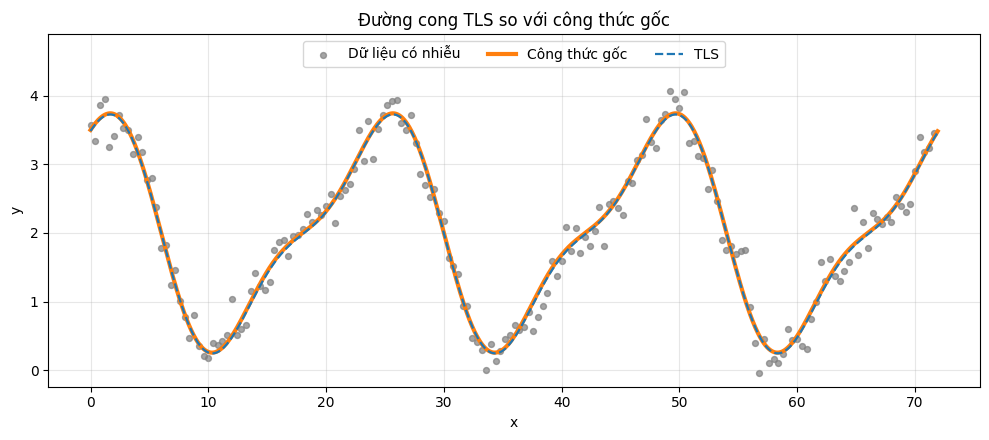

In [5]:
x_plot = np.linspace(0, 72, 1000, endpoint=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(x, y, s=18, color="tab:gray", alpha=0.7, label="Dữ liệu có nhiễu")
ax.plot(x_plot, f(x_plot), lw=3, color="tab:orange", label="Công thức gốc")
ax.plot(x_plot, design_matrix(x_plot, T, K) @ beta_svd, lw=1.6, ls="--", color="tab:blue", label="TLS")
ax.set(xlabel="x", ylabel="y", title="Đường cong TLS so với công thức gốc")
ax.set_ylim(top=4.9)
ax.grid(alpha=0.3)
ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
plt.show()